In [1]:
%matplotlib inline
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import scipy
from scipy import stats
import pandas as pd
plt.rcParams["figure.figsize"] = (20,15)

# Problem 1
### 1A

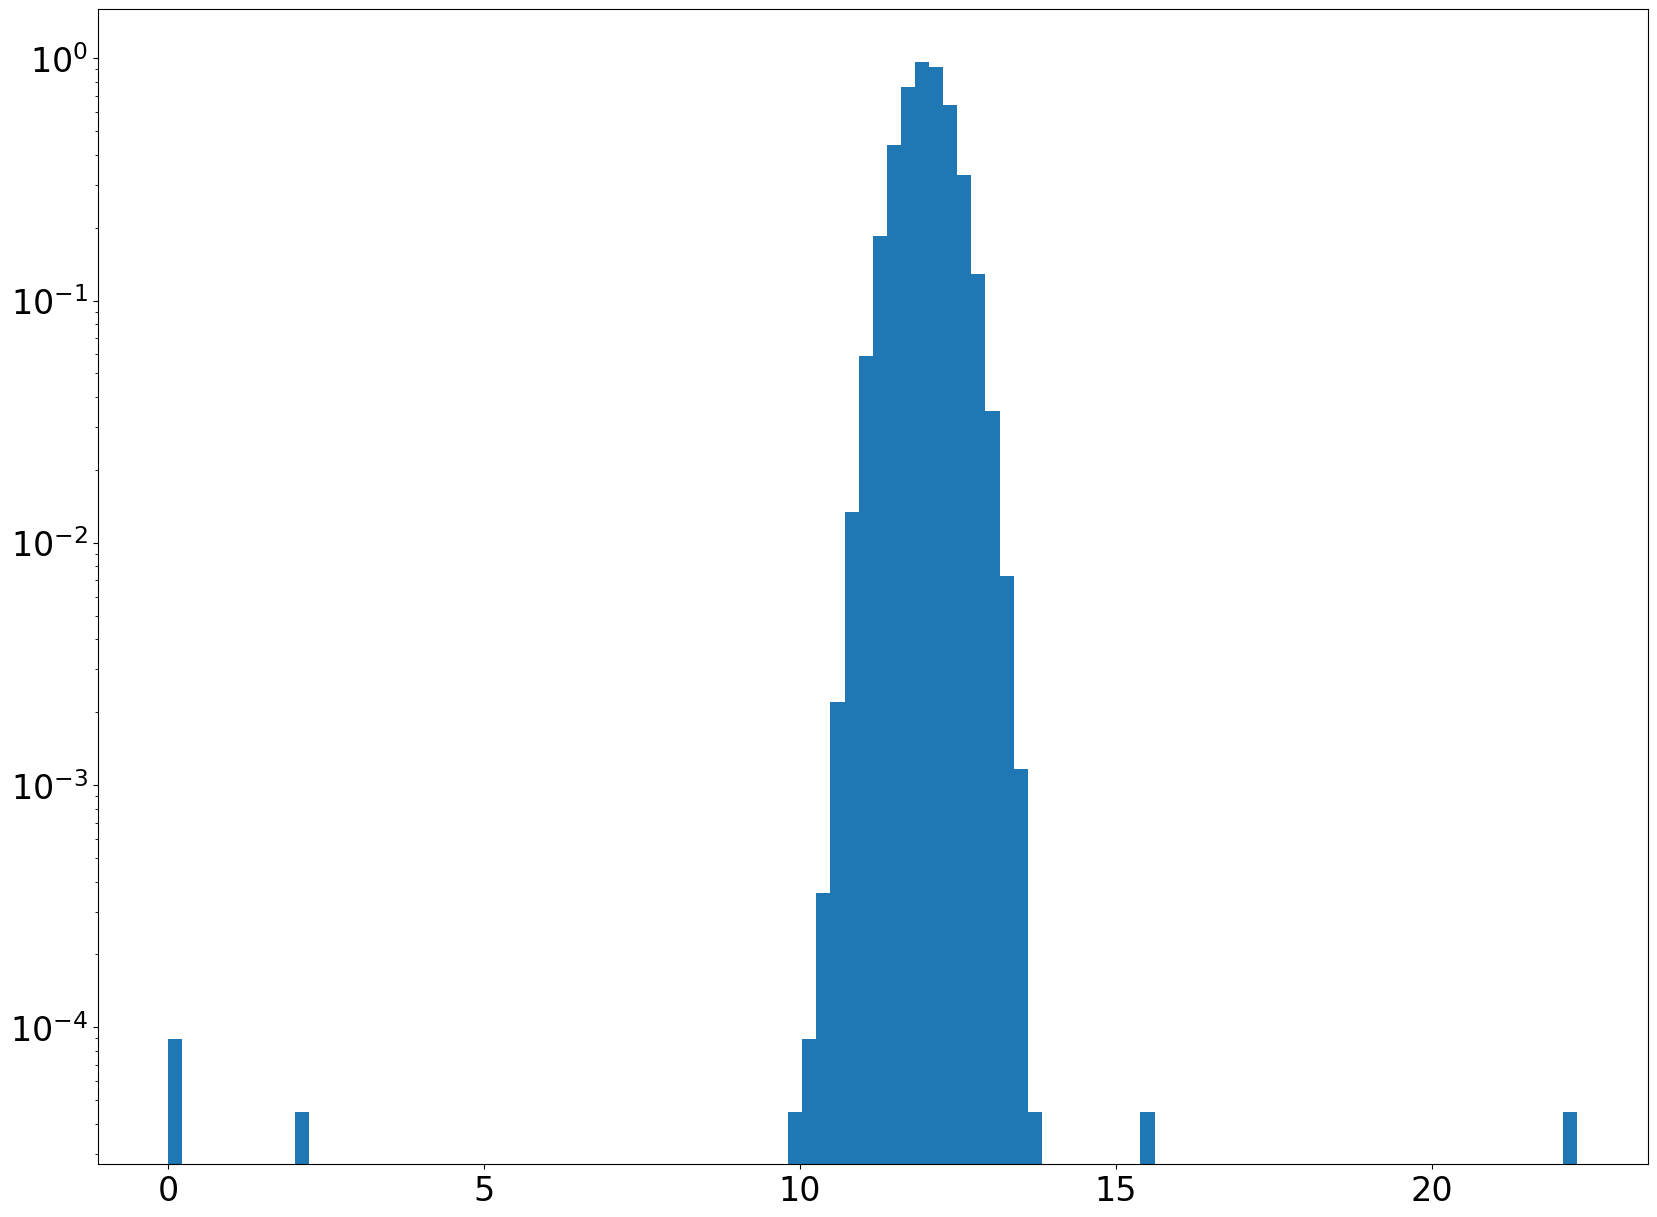

In [2]:
#I added random_state to lock the seed of rvs. Tbad is True bad data.
Tbad=[10., 10.3, 2.1, 0., 0., 15.6, 22.3, 12.7]
d = np.append(stats.norm.rvs(loc = 12., scale = 0.4, size = 100000, random_state = 42), Tbad)
fig, ax = plt.subplots(1, 1)
ax.hist(d,100, density=True)
plt.tick_params(labelsize = 24)
plt.yscale('log')
plt.show()

#### 1A.0
From the plot above, I see 5 obvious outliers at 0(2), 2.1, 15.6, 22.3. 
#### 1A.1
What is the probability that the background could yield the temperature outside of the Gaussian distribution of the signal? (test bad bad T)
#### 1A.2
The probability is the sum of probabilities from 2 tails
$$P(T) = CDF(\mu-|T-\mu|)+(1-CDF(\mu+|T-\mu|)) = 2*CDF(\mu-|T-\mu|)$$
Let's use z-value instead of P to simplify the equation.
$$z\sigma = |T-\mu|, z = \frac{|T-\mu|}{\sigma}$$
#### 1A.3

In [3]:
testbad=d[(d<10.) | (d>14.)]
testgood=d[(d>=10.) & (d<=14.)]
print(f"We know that the total True good is 100000 and total True bad is {len(Tbad)}")
print(f"The test bad bad T have {len(testbad)} elements.")
print(f"The test good bad T have {len(Tbad)-len(testbad)} elements.")

We know that the total True good is 100000 and total True bad is 8
The test bad bad T have 5 elements.
The test good bad T have 3 elements.


In [4]:
arr=np.array([[100000,0],[3,5]]) #[Col1],[Col2] Col1 has the total of 100000, Col2 has the total of 8
df=pd.DataFrame(arr.T,columns=["True T","Bad T"],index=["My Test Good","My Test Bad"]) #needed to transpose
display(df)

,True T,Bad T
My Test Good,100000,3
My Test Bad,0,5


### 1B
There are no good data threw out (test bad true T is 0). It is predictable since it follows the Normal distribution.
### 1C
There are 3 bad data getting in (test good bad T is 3). They are unavoidable since it does not need to follow Normal distribution.

# Problem 2

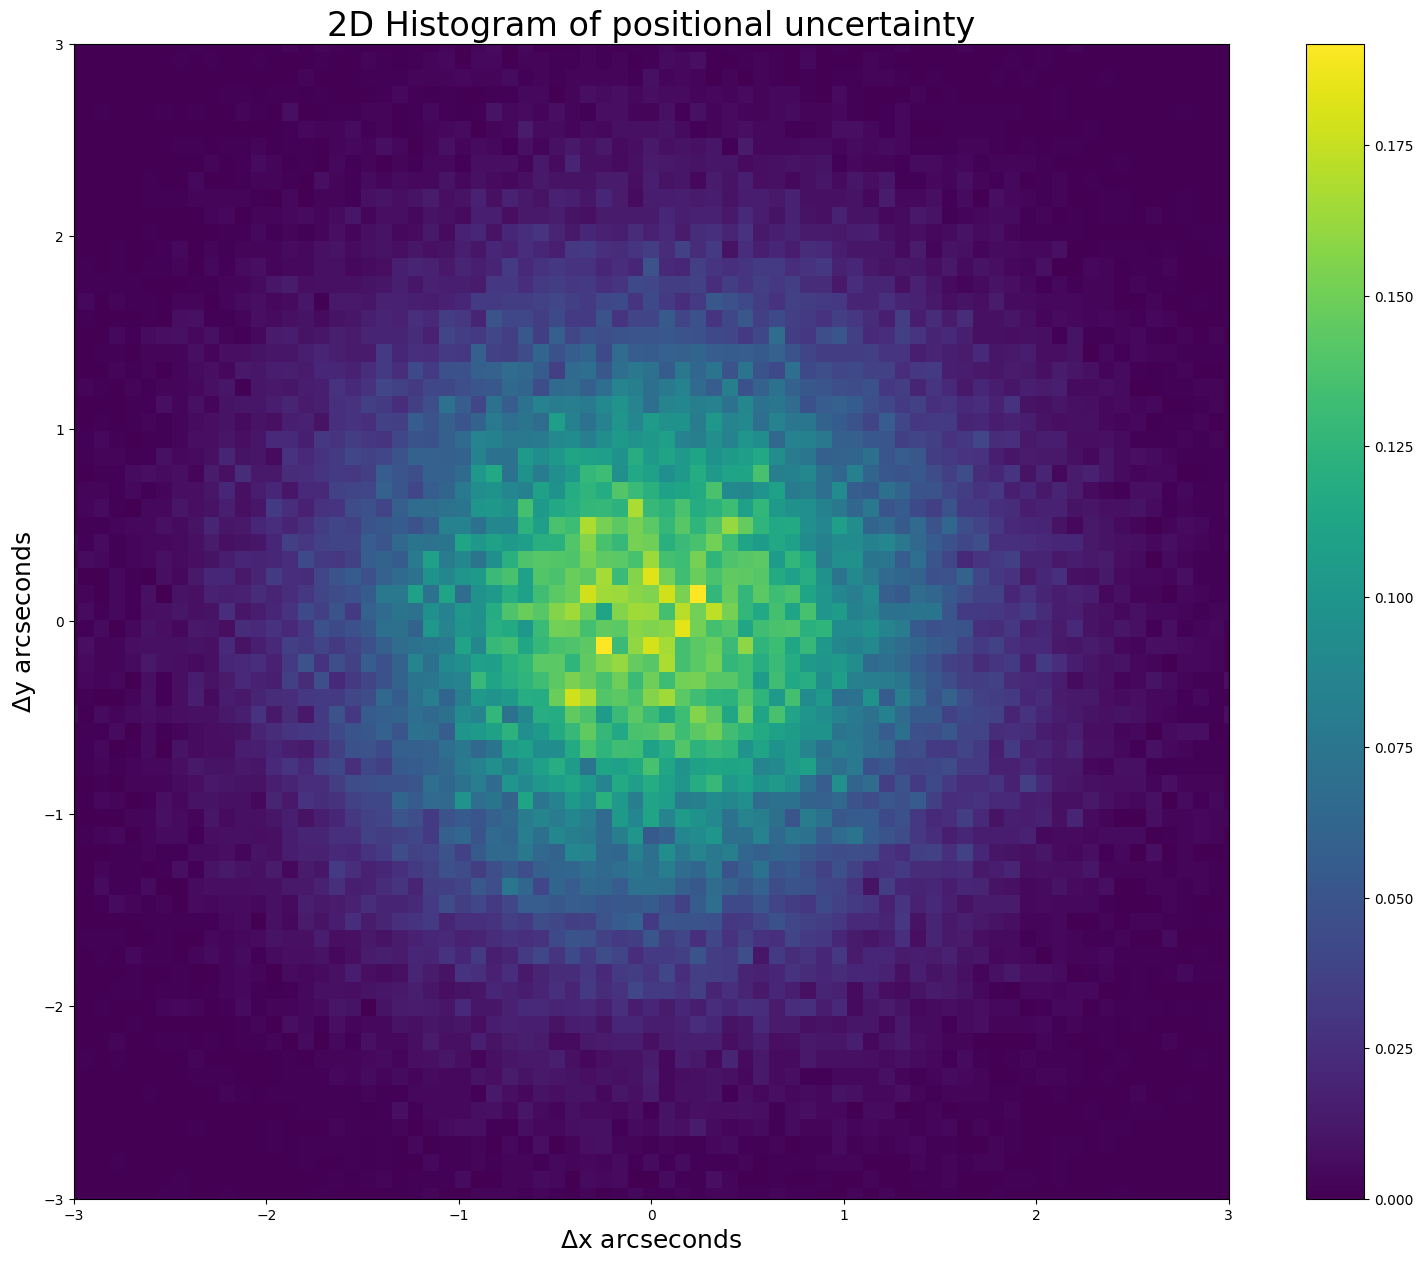

In [5]:
#I added random_state to lock the random seed of the rvs so that the results could be replicated.
#I also added delX and delY arrays to make it easier to be computed.
delX=stats.norm.rvs(scale=1,size=100000,random_state=1234)
delY=stats.norm.rvs(scale=1,size=100000,random_state=42)
a = np.vstack((delX,delY))
a.shape
fig, ax = plt.subplots(1, 1)
h = ax.hist2d(a[0,:],a[1,:],bins=100, density=True);
ax.set_aspect('equal', 'box')
plt.xlim([-3 , 3])
plt.ylim([-3 , 3])
plt.title("2D Histogram of positional uncertainty", fontsize = 24)
plt.ylabel(r"$\Delta$y arcseconds", fontsize = 18)
plt.xlabel(r"$\Delta$x arcseconds", fontsize = 18)
plt.colorbar(h[3], ax=ax)

## 2.1
What is the distance that corresponds to the significance of $5\sigma$ in this data?
## 2.2
Let's use $\Delta R = \sqrt{\Delta X^2+\Delta Y^2}$ to measure the $\sigma$ of this data


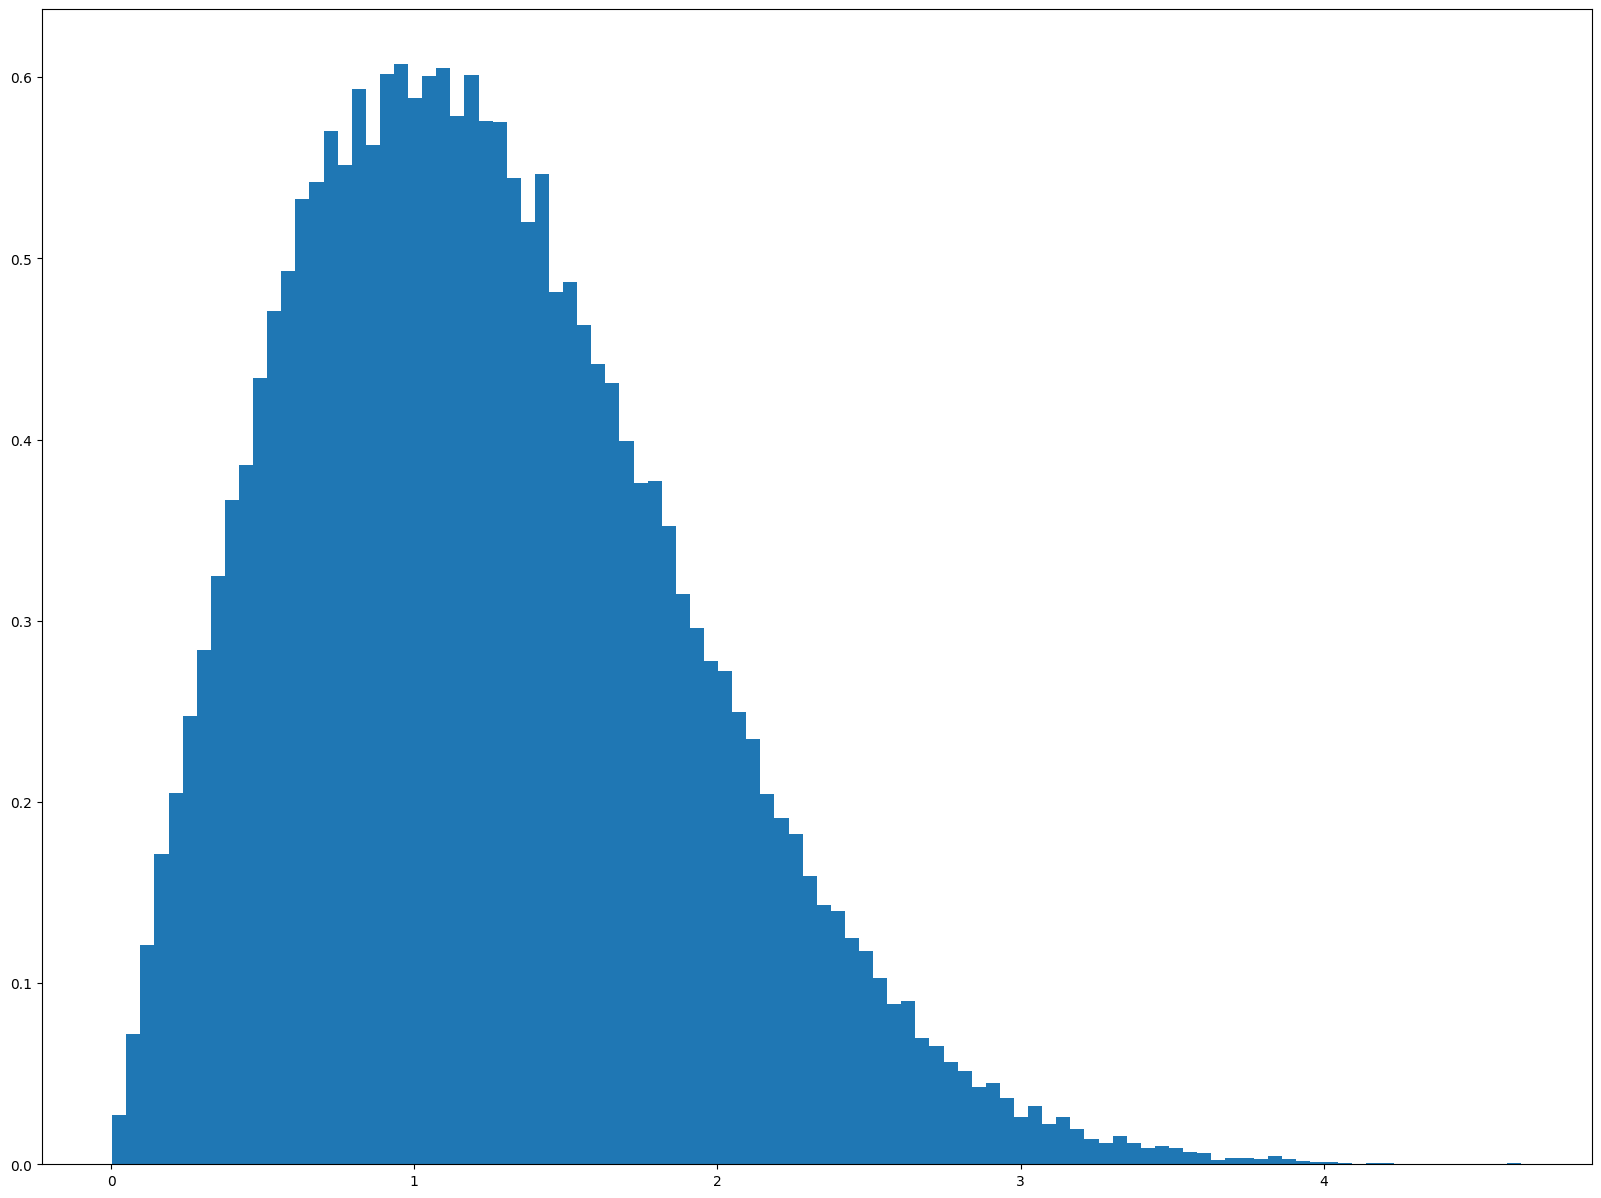

In [6]:
delR=np.sqrt(delX**2+delY**2)
plt.hist(delR,100,density=True);

First, we derive the PDF of the $\Delta R$.
$$P(\Delta X,\Delta Y) =P(\Delta X) P(\Delta Y) = \frac{1}{2\pi} e^{-\frac{\Delta X^2+\Delta Y^2}{2\sigma^2}} = \frac{1}{2\pi} 
e^{-\frac{\Delta D^2}{2\sigma^2}}$$
$$P(\Delta R) = \int_0^{2\pi} P(\Delta R,\theta) d\theta = \int_0^{2\pi} |\Delta R| P(\Delta X,\Delta Y) d\theta = 
\frac{\Delta R}{2\pi \sigma^2} e^{-\frac{\Delta D^2}{2\sigma^2}} \int_0^{2\pi} d\theta = \frac{\Delta R}{\sigma^2} 
e^{-\frac{\Delta D^2}{2\sigma^2}}$$
This looks like Rayleigh distribution.
$$CDF(\Delta R) = 1-e^{-\frac{x^2}{2\sigma^2}}, P(\Delta R_{5\sigma}) = 1-SF(5)$$
Now, we compare 2 equations together with $x=\Delta R_{5\sigma}$
## 2.3
We see that $\sigma = 1$ from the code.
$$\Delta R_{5\sigma} = \sqrt{-2\sigma^2ln(SF(5))} = \sqrt{-2ln(SF(5))}$$


In [7]:
sf5=stats.norm.sf(5)
R5=np.sqrt(-2*np.log(sf5))
print(f"The distance that corresponds to 5 sigmas from this 2D Normal distribution is {R5:.2f}\"")

The distance that corresponds to 5 sigmas from this 2D Normal distribution is 5.49"


# Problem 3
## 3.1
What is the z-value of our moon detection?
## 3.2
The amount of normal cosmic ray during 15 days would be 1 rays/min * 60 min/hr * 8 hr/day * 15 days = 7200 rays, but we see 6800. \
We can assume that the distribution of this detection is Poisson since we only have the total number of events. \
So, we use the equation $P(k,\lambda) = \frac{\lambda^k e^{-\lambda}}{k!}$. It is given that $\lambda = 7200$, so the variance of Poisson is also $\lambda = \sigma^2$.
## 3.3
We get $\sigma = \sqrt{7200}$. The z-value of 6800 could be found by using $z = \frac{x-\lambda}{\sigma}$

In [8]:
zv=(6800-7200)/np.sqrt(7200)
print(rf"The z-value of 6800 rays would be {zv:.2f} sigmas")

The z-value of 6800 rays would be -4.71 sigmas
